# Unit 4 seminar, part 2: population vs GDP per capita

**Task A (correlation):** pre-process the data to get the mean population of each country and the mean GDP per
capita from 2001 to 2021, handling missing values. Investigate the correlation, interpret the plot, and work
out the Pearson correlation coefficient.

**Task B (regression):** linear regression with mean population as the input and mean GDP per capita as the output.

Before starting, three things about the data change what has to be done:
1. `Global_GDP.csv` is **total GDP** (indicator "GDP (current US$)"), not GDP per capita. So I calculate per
   capita myself: GDP divided by population, country by country, year by year.
2. The GDP file stops at **2020**. There is no 2021 column, so the window is 2001 to 2020.
3. Both files mix real countries with **groups**, such as "World", "High income" and "Euro area". Those have to
   come out, or "World" alone becomes a massive outlier.

In [1]:
import pandas as pd                                  # tables
import numpy as np                                   # maths
import matplotlib.pyplot as plt                      # plotting
from scipy import stats                              # correlation tests

gdp = pd.read_csv("Global_GDP.csv", encoding="utf-8-sig")   # utf-8-sig removes a hidden marker at the start of the file
pop = pd.read_csv("Global_Population.csv")           # population file
print("GDP indicator:       ", gdp["Indicator Name"].unique())   # check what the GDP file actually measures
print("Population indicator:", pop["Series Name"].dropna().unique())   # and the population file
print("Last rows of the population file:")  # heading for the check below
print(pop.tail(5)[["Country Name", "Country Code"]].to_string())   # look at the end of the file for junk rows

GDP indicator:        ['GDP (current US$)']
Population indicator: ['Population, total']
Last rows of the population file:
                                                 Country Name Country Code
267                                                       NaN          NaN
268                                                       NaN          NaN
269                                                       NaN          NaN
270  Data from database: Population estimates and projections          NaN
271                                  Last Updated: 12/17/2021          NaN


The population file ends with blank rows and two lines of source notes. Those have no country code, so they go.

In [2]:
pop = pop.dropna(subset=["Country Code"])            # drop the blank rows and source notes (no country code)
dups = pop[pop["Country Code"].duplicated(keep=False)]   # any country listed more than once
print("Duplicate country codes in the population file:")  # heading for the duplicates
print(dups[["Country Name", "Country Code", "2000", "2019", "2020", "2021"]].to_string())  # show both copies side by side
# Two Aruba rows with slightly different estimates. Keep the one with more years filled in.
pop = (pop.assign(filled=pop.iloc[:, 4:].replace("..", np.nan).notna().sum(axis=1))   # count filled years per row
          .sort_values("filled", ascending=False)    # most complete rows first
          .drop_duplicates("Country Code")           # keep the first (most complete) row for each country
          .drop(columns="filled"))                   # remove the helper column

# World Bank aggregate codes (regions, income groups, lending groups, demographic groups, world).
AGGREGATES = ["AFE", "AFW", "ARB", "CEB", "CSS", "EAP", "EAR", "EAS", "ECA", "ECS", "EMU", "EUU", "FCS", "HIC",  # codes for groups of countries, not countries
              "HPC", "IBD", "IBT", "IDA", "IDB", "IDX", "INX", "LAC", "LCN", "LDC", "LIC", "LMC", "LMY", "LTE",  # (list continues)
              "MEA", "MIC", "MNA", "NAC", "OED", "OSS", "PRE", "PSS", "PST", "SAS", "SSA", "SSF", "SST", "TEA",  # (list continues)
              "TEC", "TLA", "TMN", "TSA", "TSS", "UMC", "WLD"]  # (end of list; WLD = World)
removed = gdp[gdp["Country Code"].isin(AGGREGATES)][["Country Code", "Country Name"]]   # the rows about to go
print(f"Removing {len(removed)} group rows. Check by eye that none of these is a real country:")  # how many groups are being removed
print(", ".join(removed["Country Name"]))            # list their names so the removal can be checked
gdp = gdp[~gdp["Country Code"].isin(AGGREGATES)]     # remove groups from the GDP file
pop = pop[~pop["Country Code"].isin(AGGREGATES)]     # and from the population file
print(f"\n{len(gdp)} countries left in the GDP file, {len(pop)} in the population file.")  # how many real countries remain in each file

Duplicate country codes in the population file:
   Country Name Country Code   2000    2019    2020    2021
0         Aruba          ABW  90853  106314     NaN     NaN
13        Aruba          ABW  90866  106310  106766  107000
Removing 49 group rows. Check by eye that none of these is a real country:
Africa Eastern and Southern, Africa Western and Central, Arab World, Central Europe and the Baltics, Caribbean small states, East Asia & Pacific (excluding high income), Early-demographic dividend, East Asia & Pacific, Europe & Central Asia (excluding high income), Europe & Central Asia, Euro area, European Union, Fragile and conflict affected situations, High income, Heavily indebted poor countries (HIPC), IBRD only, IDA & IBRD total, IDA total, IDA blend, IDA only, Not classified, Latin America & Caribbean (excluding high income), Latin America & Caribbean, Least developed countries: UN classification, Low income, Lower middle income, Low & middle income, Late-demographic dividend, Midd

### Missing values

In [3]:
years = [str(y) for y in range(2001, 2021)]          # the 20 year columns, 2001 to 2020
g = gdp.set_index("Country Code")[years].apply(pd.to_numeric, errors="coerce")   # GDP as numbers, one row per country
p = pop.set_index("Country Code")[years].replace("..", np.nan).apply(pd.to_numeric, errors="coerce")   # ".." means missing
g, p = g.align(p, join="inner")                      # keep only countries in both files, in the same order
names = gdp.set_index("Country Code")["Country Name"]   # lookup from code to readable name

per_capita = g / p                      # GDP per person, per country, per year
years_present = per_capita.notna().sum(axis=1)       # how many of the 20 years each country has
print("How many of the 20 years have a GDP-per-capita value, per country:")  # heading for the count below
print(years_present.value_counts().sort_index(ascending=False).to_string())   # e.g. "20 years: 185 countries"
print("\nCountries with no GDP at all in the window:", ", ".join(names[years_present == 0]))  # countries with nothing to average

How many of the 20 years have a GDP-per-capita value, per country:
20    185
19     13
18      4
15      1
14      1
13      1
11      2
10      1
8       3
7       1
0       5

Countries with no GDP at all in the window: Gibraltar, St. Martin (French part), Korea, Dem. People's Rep., French Polynesia, British Virgin Islands


**My rule for missing years:** take the mean over the years that do exist, but only for countries with at
least 10 of the 20 years. A mean of 2 years isn't comparable with a mean of 20, especially over a period
that includes the 2008 crash and the 2020 pandemic. Filling the gaps with zero would be wrong, because zero
GDP isn't "no data". Filling with the global average would be invented.

In [4]:
keep = years_present >= 10                           # True for countries with at least 10 years of data
data = pd.DataFrame({                                # one row per kept country
    "country": names[keep.index[keep]],              # readable name
    "mean_population": p[keep].mean(axis=1),         # average population over the years available
    "mean_gdp_per_capita": per_capita[keep].mean(axis=1),   # average GDP per person over the years available
})
print(f"Kept {keep.sum()} countries, dropped {(~keep).sum()}:", ", ".join(names[keep.index[~keep]]))  # kept count, and the names of those dropped
data.sort_values("mean_gdp_per_capita", ascending=False).head(5)   # the five richest per head, as a sense check

Kept 208 countries, dropped 9: Channel Islands, Gibraltar, St. Martin (French part), Korea, Dem. People's Rep., French Polynesia, Somalia, South Sudan, Sint Maarten (Dutch part), British Virgin Islands


,country,mean_population,mean_gdp_per_capita
Country Code,,,
MCO,Monaco,35897.45,152610.101196
LIE,Liechtenstein,36110.75,138115.293315
LUX,Luxembourg,523287.55,100267.387806
BMU,Bermuda,64348.95,94780.323307
CYM,Cayman Islands,56101.50,79772.726331


## Task A: correlation

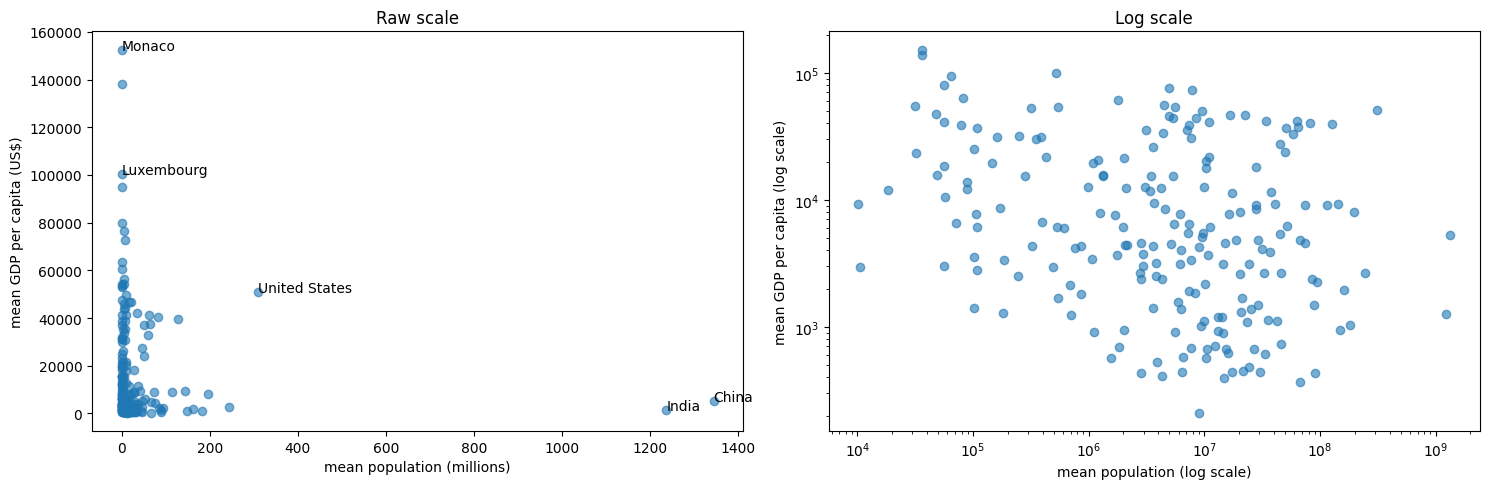

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))      # raw scale and log scale side by side
axes[0].scatter(data.mean_population / 1e6, data.mean_gdp_per_capita, alpha=0.6)   # population in millions
axes[0].set_xlabel("mean population (millions)"); axes[0].set_ylabel("mean GDP per capita (US$)")  # axis labels
axes[0].set_title("Raw scale")  # left plot title
for code_ in ["CHN", "IND", "USA", "LUX", "MCO"]:     # label a few countries that stand out
    if code_ in data.index:  # only label countries that survived cleaning
        axes[0].annotate(data.loc[code_, "country"], (data.loc[code_, "mean_population"] / 1e6, data.loc[code_, "mean_gdp_per_capita"]))  # write the country name next to its point
axes[1].scatter(data.mean_population, data.mean_gdp_per_capita, alpha=0.6)   # same data again
axes[1].set_xscale("log"); axes[1].set_yscale("log") # log scales spread out the crowded corner
axes[1].set_xlabel("mean population (log scale)"); axes[1].set_ylabel("mean GDP per capita (log scale)")  # axis labels
axes[1].set_title("Log scale")  # right plot title
plt.tight_layout(); plt.show()                       # draw

In [6]:
r, p_val = stats.pearsonr(data.mean_population, data.mean_gdp_per_capita)    # the task's Pearson coefficient
r_log, p_log = stats.pearsonr(np.log10(data.mean_population), np.log10(data.mean_gdp_per_capita))   # on log scales
rho, p_rho = stats.spearmanr(data.mean_population, data.mean_gdp_per_capita)  # rank-based, ignores the shape
print(f"Pearson r (raw values):        {r:6.3f}   p = {p_val:.3f}")  # the task's answer
print(f"Pearson r (log of both):       {r_log:6.3f}   p = {p_log:.3f}")  # same test on log scales
print(f"Spearman rho (rank order):     {rho:6.3f}   p = {p_rho:.3f}")  # rank-based check

no_giants = data[~data.index.isin(["CHN", "IND"])]  # check the result isn't just China and India
print(f"\nPearson r without China and India: {stats.pearsonr(no_giants.mean_population, no_giants.mean_gdp_per_capita)[0]:.3f}")  # does the result depend on the two giants?

Pearson r (raw values):        -0.067   p = 0.339
Pearson r (log of both):       -0.296   p = 0.000
Spearman rho (rank order):     -0.270   p = 0.000

Pearson r without China and India: -0.054


## Task B: regression

GDP per capita = 15,883 + -0.00001166 x population
Per extra 10 million people: -117 US$ per head
R² on all countries: 0.0044
Cross-validated R² (unseen countries): -0.015

Log-log model R²: 0.0873, slope -0.188


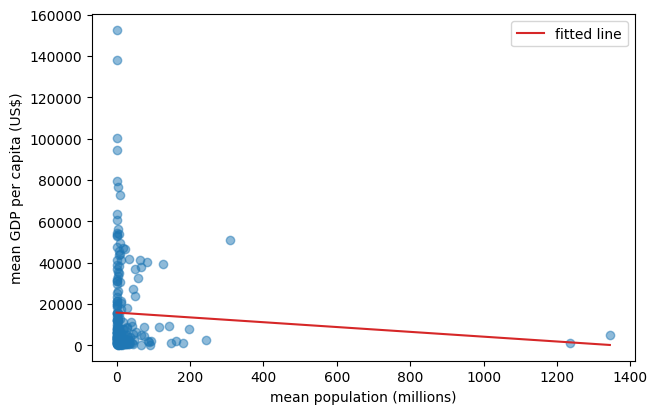

In [7]:
from sklearn.linear_model import LinearRegression    # straight-line model
from sklearn.model_selection import cross_val_score, KFold   # test on unseen countries

X = data[["mean_population"]].values                 # input: mean population (as a single column)
y = data["mean_gdp_per_capita"].values               # output: mean GDP per capita
model = LinearRegression().fit(X, y)                 # fit the line, as the task asks
print(f"GDP per capita = {model.intercept_:,.0f} + {model.coef_[0]:.8f} x population")   # the fitted equation
print(f"Per extra 10 million people: {model.coef_[0] * 1e7:,.0f} US$ per head")   # the slope in readable units
print(f"R² on all countries: {model.score(X, y):.4f}")   # share of the variation the line explains
cv = KFold(5, shuffle=True, random_state=0)          # 5 folds, shuffled
print(f"Cross-validated R² (unseen countries): {cross_val_score(LinearRegression(), X, y, cv=cv, scoring='r2').mean():.3f}")  # average R² on countries left out of training

Xl, yl = np.log10(X), np.log10(y)                    # the same data on log scales
log_model = LinearRegression().fit(Xl, yl)           # a line through the log-log cloud
print(f"\nLog-log model R²: {log_model.score(Xl, yl):.4f}, slope {log_model.coef_[0]:.3f}")  # fit and slope of the log-log line

plt.figure(figsize=(7, 4.5))                         # one plot
plt.scatter(X / 1e6, y, alpha=0.5)                   # the countries
xs = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)   # x positions to draw the line through
plt.plot(xs / 1e6, model.predict(xs), color="tab:red", label="fitted line")   # the regression line
plt.xlabel("mean population (millions)"); plt.ylabel("mean GDP per capita (US$)"); plt.legend(); plt.show()  # labels, legend and draw

## What I took from it


- **The data needed more fixing than the task suggested.** The "GDP" file is total GDP, not per capita, so I
  calculated per capita myself. It only runs to 2020. Aruba appears twice with slightly different figures.
  Forty-nine of the rows are groups, not countries. Any one of these, missed, would have given a wrong answer
  that still looked fine.
- **Missing values:** 185 of 217 countries have all 20 years. I kept countries with at least 10 years and
  averaged what they had. That dropped 9, mostly small territories, plus Somalia, South Sudan and North Korea,
  where conflict or secrecy means the data simply isn't there. The countries missing from a dataset are often
  not missing at random.
- **The plot:** on the raw scale, almost every country is crushed into the bottom-left corner. China and India
  sit far out on their own. The richest places per head, like Monaco, Liechtenstein, Luxembourg and Bermuda,
  are all tiny. On a log scale you can see the cloud properly, and it has no clear direction.
- **Pearson correlation is −0.067 (p = 0.34).** In plain words: there is no straight-line relationship between
  how many people a country has and how rich each person is. Removing China and India barely changes it
  (−0.054).
- **There is a weak pattern once the scale is fixed.** On logs (−0.296), or by rank (Spearman −0.270), smaller
  countries tend to be a bit richer per head, and that is statistically significant. It's driven by the
  micro-states and tax havens at the top of the table. It's a weak tendency, not a law.
- **Task B confirms it.** The fitted line says each extra 10 million people means $117 less GDP per head, but
  R² is 0.0044. Population explains less than half a percent of the differences in wealth. On countries the
  model hasn't seen, R² goes negative (−0.015): it does worse than just guessing the average. Even the log
  version only reaches 0.087.
- **What it means:** you can run a regression on anything and get a slope. A slope with an R² near zero is the
  model telling you the input doesn't explain the output. Wealth per head is driven by things like
  productivity, resources, institutions and history, none of which are in this data.